# Joint depth–label GP: a step-by-step walkthrough

**What this notebook covers:** it explains the model, fits it to one real Stage M checkpoint, makes one paid update, computes one acquisition decision, and then shows the study's actual results.
- Everything uses the frozen Stage M priors and the repository port `src/jdl_model.py`.
- The demonstration checkpoint is NEW DEV repeat 1, fold 1, which is Stage M data. The acquisition shown here is an illustration, not a Stage A result.

**The model.**

$$f \sim GP(0, k_f),\quad \theta \sim N(0, 0.35^2),\quad \delta \sim GP(0, k_\delta^{c}),\qquad h(x) = f(x) - \theta + \delta(x)$$
$$z = \log(A/111\,\mu m) \mid f \sim N(f, 0.03^2),\qquad Y \mid h \sim \mathrm{Bernoulli}\{\Phi(h/0.15)\}$$

- **Response:** f is the log active-window depth relative to 111 µm.
- **Threshold:** θ is an uncertain global threshold.
- **Discrepancy:** δ is a smooth discrepancy, centred on the fixed feature-only candidate pool.
- **Inference:** the paid responses condition f exactly; a joint probit Laplace step then adds the paid labels. Every cross-covariance between f, θ and δ is kept.
- **Information contract:** the learner sees paid rows only. Test labels and test depths are used only by the evaluator.

In [1]:
import numpy as np, pandas as pd, json
from scipy.special import ndtr
import src.jdl_model as JM
import src.jdl_stage_m as SMM
cfg = JM.STAGE_M_CONFIG
print({k: v for k, v in cfg.__dict__.items()})
man = json.loads((SMM.OUT / 'STUDY_MANIFEST.json').read_text(encoding='utf-8'))
print('frozen manifest written', man['written_utc'], '| primary contrast:', man['primary_contrast'])

{'f_amplitude': 0.6, 'f_lengthscale': (1.5, 1.5, 1.5, 1.5), 'discrepancy_amplitude': 0.35, 'discrepancy_lengthscale': (1.5, 1.5, 1.5, 1.5), 'threshold_mean': 0.0, 'threshold_sd': 0.35, 'response_noise_sd': 0.03, 'probit_scale': 0.15, 'f_mean': 0.0, 'jitter': 1e-10}
frozen manifest written 2026-10-13T13:45:05+00:00 | primary contrast: NEW, B40, BA: J - Binary_matched


## 1. One real checkpoint: NEW, repeat 1, fold 1, B16 (feature-only maximin prefix)

- **What the oracle returns:** only the paid rows' outcomes, as (Y, z). The missing-A run keeps its label with z = NaN.
- **Inputs:** log(P, VX, LS, ST), standardized over the fold's pool.

In [2]:
task = [t for t in SMM.build_tasks() if (t['population'], t['repeat'], t['fold']) == ('NEW', 1, 1)][0]
paths = pd.read_csv(SMM.SM / 'paths.csv')
g = paths[(paths.population == 'NEW') & (paths.repeat == 1) & (paths.fold == 1)].sort_values('query_index')
pos = {s: i for i, s in enumerate(task['ids'])}; task['path'] = g.sim_id.map(pos).to_numpy(int)
std, scaler = SMM.standardizer(task)
paid = SMM.Oracle(task).reveal(task['path'][:16])
print('paid simulations:', len(paid.ids), '| positives', int(paid.y.sum()), '| negatives', int((paid.y == 0).sum()), '| responses', int(np.isfinite(paid.z).sum()))
print(pd.DataFrame({'Y': paid.y, 'z=log(A/111)': np.round(paid.z, 3), 'sim_id (full)': paid.ids}).head(8).to_string(index=False))
model = JM.JointDepthLabelGP(std(task['X'][task['pool']]), cfg).fit(std(paid.X), paid.y, paid.z)
print({k: model.diagnostics[k] for k in ('solver_status', 'gradient_inf', 'gradient_accepted', 'newton_iterations')})
post = model.marginals(std(task['X'][task['test']]))
print('theta posterior: mean %.3f, sd %.3f (prior sd 0.35)' % (post['theta_mean'], np.sqrt(post['theta_var'])))

paid simulations: 16 | positives 15 | negatives 1 | responses 16
 Y  z=log(A/111)                                                                                                                                            sim_id (full)
 1         1.011 P-364p438052531_VX-0p255656166147_LS-4p37253236925e-05_ST-405p223461382_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-1p88695648367e-05_H-a9810bc3b3
 0         0.068 P-426p768553369_VX-0p970152058637_LS-4p12602194162e-05_ST-379p997827854_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-4p97254070645e-06_H-b2eec677b1
 1        -0.340   P-351p92267109_VX-0p98107853237_LS-4p98248594664e-05_ST-477p481832276_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-4p91716049617e-06_H-349225d53c
 1         1.004    P-446p4215361_VX-0p360448552559_LS-4p80408789123e-05_ST-355p77328211_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-1p33836592456e-05_H-726ce7648f
 1         0.118 P-380p999402419_VX-0p875337770389_LS-4p81159771741e-05_ST-321p053866

## 2. What a prediction is made of

Each test probability is Φ(μ_h / √(τ² + V_h)), with μ_h = μ_f − μ_θ + μ_δ. The label column is shown for the reader only; the model never sees it.

Simulations are identified by their full IDs. The H suffix alone is not unique: two test simulations in this very fold end in `H-24e1882408`, a suffix shared by 14 NEW simulations.

In [3]:
te = task['test']
tab = pd.DataFrame({'VX': task['VX'][te].round(3), 'f (pred z)': post['f_mean'].round(3),
                    'theta': round(post['theta_mean'], 3), 'delta': post['delta_mean'].round(3), 'h': post['h_mean'].round(3),
                    'sd(h)': np.sqrt(post['h_var']).round(3), 'p': post['p'].round(3), 'label (evaluator only)': task['y'][te],
                    'sim_id (full)': [task['ids'][i] for i in te]})
print(tab.sort_values('p').head(10).to_string(index=False))

   VX  f (pred z)  theta  delta     h  sd(h)     p  label (evaluator only)                                                                                                                                            sim_id (full)
0.960       0.128  -0.12  0.085 0.333  0.465 0.752                       0  P-387p361336282_VX-0p960187357846_LS-4p72484046084e-05_ST-390p52586458_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-5p02414509376e-06_H-b302fc6cbd
0.961       0.231  -0.12  0.075 0.426  0.497 0.794                       0  P-361p800115091_VX-0p960992922817_LS-4p74221265218e-05_ST-336p90191265_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-5p01993353798e-06_H-6f28bdc6c9
0.954       0.443  -0.12 -0.013 0.550  0.619 0.806                       0 P-353p784791664_VX-0p953661701626_LS-4p00659722232e-05_ST-310p795032219_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-5p05852399734e-06_H-f4fc937e86
0.625       0.200  -0.12  0.205 0.525  0.525 0.832                       1 P-363p5932931

## 3. One paid update

- **What happens:** the next simulation on the frozen path is paid, and its label and response are revealed together.
- **How the model updates:** it is refit from the original prior with every paid likelihood factor exactly once. The old posterior is never reused as a new prior.

In [4]:
paid17 = SMM.Oracle(task).reveal(task['path'][:17])
new = paid17.ids[-1]
print('revealed:', new, '| Y =', paid17.y[-1], '| z =', round(float(paid17.z[-1]), 3))
model17 = JM.JointDepthLabelGP(std(task['X'][task['pool']]), cfg).fit(std(paid17.X), paid17.y, paid17.z)
post17 = model17.marginals(std(task['X'][te]))
xref = std(task['X'][task['pool']])
print('theta: %.3f -> %.3f | sd %.3f -> %.3f' % (post['theta_mean'], post17['theta_mean'], np.sqrt(post['theta_var']), np.sqrt(post17['theta_var'])))
print('integrated Var[pi] over the pool: %.5f -> %.5f' % (model.integrated_probability_variance(xref).mean(), model17.integrated_probability_variance(xref).mean()))
print('largest change in a test probability: %.3f' % np.max(np.abs(post17['p'] - post['p'])))

revealed: P-404p339337235_VX-0p581538315652_LS-4p14188299047e-05_ST-443p216543835_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-8p2954475624e-06_H-d0ad4c3a0a | Y = 1 | z = 1.002
theta: -0.120 -> -0.120 | sd 0.192 -> 0.192
integrated Var[pi] over the pool: 0.04800 -> 0.04472
largest change in a test probability: 0.031


## 4. One acquisition calculation (paired probability-variance reduction)

For a candidate j the score is the expected reduction of the pool-averaged Var[Φ(h/τ)] after observing (Z_j, Y_j) together:

$$a(j) = E_{Z_j}\sum_i w_i\Big[(p_i(Z_j) - p_i)^2 + \frac{\{J_{ij}(Z_j) - p_i(Z_j)q(Z_j)\}^2}{q(Z_j)[1-q(Z_j)]}\Big].$$

- **Integration over Z:** Gauss–Hermite.
- **J_ij:** a bivariate normal CDF (Genz).
- **Ranking rule:** compare 15 and 31 nodes, and accept the top candidate if its gap exceeds 2e plus the tail bound. Otherwise use 63 nodes, then a tie or a STOP. There is no fallback to margin.
- **Status:** an illustration on Stage M data, not a Stage A result.

In [5]:
from src.jdl_stage_a import select_pv, select_margin
cand = np.setdiff1d(task['pool'], task['path'][:16]); cid = [task['ids'][i] for i in cand]
log = []
j, rec = select_pv(model, std(task['X'][cand]), cid, xref, log)
s = pd.DataFrame([r for r in log if r['gh_order'] == 31]).sort_values('score', ascending=False).head(5)
print(s[['score', 'response_component', 'label_component', 'candidate']].round(6).to_string(index=False))
print('decision:', rec['decision'], '| e(15,31) = %.2e, gap = %.2e' % (rec['e_15_31'], rec['gap_31']))
jm, recm = select_margin(model, std(task['X'][cand]), cid, [])
print('probability-variance pick:', rec['selected'])
print('margin pick:              ', recm['selected'])

   score  response_component  label_component                                                                                                                                                candidate
0.001875            0.001228         0.000647 P-375p241878479_VX-0p685894067448_LS-4p82788734336e-05_ST-477p796721129_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-7p03333186853e-06_H-f207dd3a17
0.001820            0.001024         0.000796  P-391p835745622_VX-0p97812625082_LS-4p53819703986e-05_ST-409p919098726_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-4p93200197722e-06_H-24e1882408
0.001794            0.001079         0.000715 P-380p582137919_VX-0p978166332261_LS-4p83858659008e-05_ST-415p110382592_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-4p93179988302e-06_H-210d3fce7d
0.001778            0.001015         0.000763  P-380p041479483_VX-0p952843483906_LS-4p56527036263e-05_ST-376p177191048_M-TI64_XI-0p0002_XF-0p0014_XL-0p0012_TE-0p0021_DT-5p0628678104e-06_H-b7e3ed2e12
0.001

## 5. The actual results

In [6]:
dec = json.loads((SMM.SM / 'STAGE_M_DECISION.json').read_text(encoding='utf-8'))
print('Stage M screen:', dec['decision'], '|', dec['NEW_B40_J_minus_Binary'])
m = pd.read_csv(SMM.SM / 'metrics_per_repeat.csv')
print(m[(m.population == 'NEW') & (m.budget == 40)].groupby('arm')[['BA', 'specificity', 'log_loss', 'AUC']].mean().round(3).to_string())
ta = pd.read_csv(SMM.OUT / 'mechanism/POSTHOC_threshold_alignment.csv')
print(ta[(ta.population == 'NEW') & (ta.budget == 40)].groupby('arm')[['BA_at_0.5', 'BA_at_paid_prevalence']].mean().round(3).to_string())

Stage M screen: SCREEN FAILED - Stage A not recommended | {'BA': 0.006048387096774188, 'BA_interval': [-0.052419354838709686, 0.06451612903225806], 'specificity': -6.938893903907228e-18, 'log_loss': -0.1715458450391908, 'BA_per_repeat': [-0.03360215053763438, 0.045698924731182755]}
                   BA  specificity  log_loss    AUC
arm                                                
ACTIVE_E1       0.730        0.500     0.799  0.893
Binary_matched  0.546        0.125     0.384  0.800
G3              0.618        0.292     0.307  0.819
J               0.552        0.125     0.212  0.873
J_fixed_theta   0.552        0.125     0.208  0.878
J_no_delta      0.575        0.167     0.211  0.876
                BA_at_0.5  BA_at_paid_prevalence
arm                                             
ACTIVE_E1           0.730                  0.784
Binary_matched      0.546                  0.504
G3                  0.618                  0.722
J                   0.552                  0.870
J_fixed

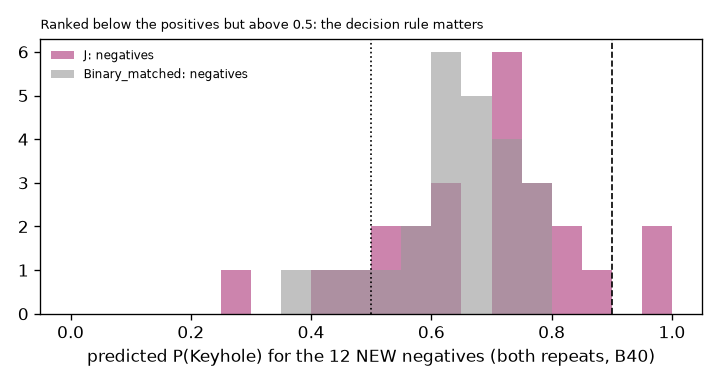

In [7]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.2))
pr = pd.read_csv(SMM.SM / 'predictions_all.csv.gz')
yv = dict(zip(task['ids'], task['y']))
for arm, c in (('J', '#AA3377'), ('Binary_matched', '#999999')):
    g2 = pr[(pr.population == 'NEW') & (pr.budget == 40) & (pr.arm == arm)]
    lab = g2.sim_id.map(yv)
    ax.hist(g2.p[lab == 0], bins=20, range=(0, 1), alpha=.6, color=c, label=f'{arm}: negatives')
ax.axvline(0.5, color='k', ls=':', lw=1); ax.axvline(0.9, color='k', ls='--', lw=1)
ax.set_xlabel('predicted P(Keyhole) for the 12 NEW negatives (both repeats, B40)'); ax.legend(fontsize=7, frameon=False)
ax.set_title('Ranked below the positives but above 0.5: the decision rule matters', fontsize=8, loc='left')
plt.tight_layout(); plt.show()

In [8]:
for name in ('exploratory/EX1_ba_aligned_decision_rule/EX1_RESULTS.json', 'exploratory/EX2_trained_response_prior/EX2_RESULTS.json'):
    p = SMM.OUT / name
    print(name, '->', json.dumps(json.loads(p.read_text(encoding='utf-8')), default=float)[:900] if p.exists() else 'not available')
tr = SMM.OUT / 'temporal_repair/summary_trajectory.csv'
print(pd.read_csv(tr).round(3).to_string() if tr.exists() else 'temporal repair: not available')

exploratory/EX1_ba_aligned_decision_rule/EX1_RESULTS.json -> {"EX1-P1_primary": {"estimate": 0.33467741935483875, "interval": [0.24091061827956992, 0.4193632392473117], "per_repeat": [0.34408602150537637, 0.3104838709677419, 0.34005376344086025, 0.34408602150537637], "supported": true}, "EX1-P2_mechanism": {"specificity": 0.8125, "sensitivity": -0.14314516129032256, "supported": true}, "EX1-P3_control": {"estimate": -0.06720430107526881, "interval": [-0.13272849462365593, -0.012096774193548404], "supported": true}, "EX1-P4_system": {"estimate": 0.19590053763440857, "interval": [0.07358870967741934, 0.3178931451612902], "supported": true}, "fits": 320, "fit_statuses": {"ok": 320}}
exploratory/EX2_trained_response_prior/EX2_RESULTS.json -> {"EX2-P1_response": {"estimate_all": -0.09124562491305367, "interval": [-0.11285942670196394, -0.07011251690450102], "fast_scan_rmse": {"J": 0.23567240062081482, "J_trained": 0.11673199894800873}, "supported": true}, "EX2-P2_labels": {"BA_at_pi_hat": 0

## 6. Reading the results

- **What depth adds.** Paid continuous depth adds label information on OLD and POOLED, and improves NEW ranking and probability quality.
- **Why the screen failed.** The frozen NEW screen requires a balanced-accuracy gain at p ≥ 0.5 and it failed. The diagnostics point to the decision threshold under 91 % prevalence, to over-smoothed depth predictions in the fast-scan corner, and to 12 negatives being too few to resolve +0.01 BA.
- **The exploratory tests (fresh DEV repeats 5–8, manifests committed before any fit).**
  - EX1: predicting Keyhole when p ≥ π̂ (the paid prevalence) instead of p ≥ 0.5 raised NEW B40 J balanced accuracy from 0.543 to 0.878 (+0.335, interval +0.241 to +0.419), with specificity +0.81 and sensitivity −0.14. The same rule *lowered* Binary-matched BA (−0.067), so the gain is not a generic threshold effect.
  - EX2: a response prior trained on the paid depths (ML-II) halved the fast-scan depth error (RMSE 0.236 → 0.117) and added +0.028 BA at π̂ (interval +0.012 to +0.047).
  - Both are exploratory. Neither changes the frozen Stage M decision, and neither has been confirmed on reserved data.
- **What the gain consists of (POST-HOC, `exploratory/EXPLORATORY_REPORT.md` §3).**
  - At p ≥ π̂, the joint model labels the whole fast-scan corner (VX > 0.85 m/s) "no Keyhole": all 11 fast negatives are rejected and nearly all 12 fast positives are missed.
  - None of the tested models separated the cases inside that corner. This does not show that no discriminator exists.
  - The one persistent false positive is a slow scan whose recording ended early and which has no A.
- **Errata of 2026-10-14.**
  - p ≥ π̂ is a train-only heuristic: the paid fraction is not an unbiased prevalence estimate.
  - Its global BA gain costs short-K detection (J_trained 0.675 → 0.05), so J_trained at 0.5 remains a serious comparator.
  - Small ablation effects do not establish physical (non-)identifiability.